In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error

In [3]:
import tensorflow as tf
from tensorflow import keras

In [4]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")
df = df.drop("id", axis=1)
df

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7
...,...,...,...,...,...,...,...,...,...
4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10


In [5]:
print(df.shape)
print(df.isnull().sum().sum())
print(df["Rings"].describe())

(4177, 9)
0
count    4177.000000
mean        9.933684
std         3.224169
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: Rings, dtype: float64


In [6]:
df = pd.get_dummies(df, columns=["Sex"], dtype=int)
df.head()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Sex_F,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,0,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,0,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,1,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,0,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,0,1,0


In [7]:
df["age_group"] = pd.cut(df["Rings"], bins=[0, 8, 10, 30], labels=[0, 1, 2]).astype(int)
print(df["age_group"].value_counts().sort_index())

age_group
0    1407
1    1323
2    1447
Name: count, dtype: int64


In [8]:
X = df.drop(["Rings", "age_group"], axis=1)
y = df["age_group"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

In [10]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3341, 10), (836, 10), (3341,), (836,))

Classification

In [11]:
model_dt = DecisionTreeClassifier()
model_dt.fit(X_train, y_train)

pred_dt = model_dt.predict(X_test)
print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

           0       0.66      0.67      0.66       281
           1       0.42      0.42      0.42       265
           2       0.55      0.55      0.55       290

    accuracy                           0.55       836
   macro avg       0.54      0.54      0.54       836
weighted avg       0.55      0.55      0.55       836



In [12]:
model_rf = RandomForestClassifier()
model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.77      0.77      0.77       281
           1       0.52      0.50      0.51       265
           2       0.67      0.70      0.69       290

    accuracy                           0.66       836
   macro avg       0.65      0.66      0.65       836
weighted avg       0.66      0.66      0.66       836



In [13]:
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.71      0.77      0.74       281
           1       0.47      0.44      0.45       265
           2       0.66      0.65      0.66       290

    accuracy                           0.62       836
   macro avg       0.61      0.62      0.62       836
weighted avg       0.62      0.62      0.62       836



In [14]:
model_kn = KNeighborsClassifier()
model_kn.fit(X_train, y_train)

pred_kn = model_kn.predict(X_test)
print(classification_report(y_test, pred_kn))

              precision    recall  f1-score   support

           0       0.73      0.77      0.75       281
           1       0.46      0.52      0.49       265
           2       0.69      0.57      0.62       290

    accuracy                           0.62       836
   macro avg       0.62      0.62      0.62       836
weighted avg       0.63      0.62      0.62       836



DL

In [15]:
X = df.drop(["Rings", "age_group"], axis=1).values
y = df["age_group"].values
rings = df["Rings"].values

In [16]:
X_train, X_test, y_train, y_test, rings_train, rings_test = train_test_split(
    X, y, rings, test_size=0.2, random_state=42, stratify=y)

In [17]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

DL_Binary classification

In [18]:
y_train_bin = (rings_train >= 10).astype(int)
y_test_bin = (rings_test >= 10).astype(int)
print(np.bincount(y_train_bin))

[1667 1674]


In [19]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(10,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history = model.fit(X_train, y_train_bin, epochs=100, batch_size=32, validation_split=0.2, verbose=0)

In [22]:
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()

 1/27 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [23]:
accuracy = accuracy_score(y_test_bin, y_pred)
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix")
print(confusion_matrix(y_test_bin, y_pred))
print("\nClassification Report")
print(classification_report(y_test_bin, y_pred))


Accuracy = 0.7715311004784688

Confusion Matrix
[[313 116]
 [ 75 332]]

Classification Report
              precision    recall  f1-score   support

           0       0.81      0.73      0.77       429
           1       0.74      0.82      0.78       407

    accuracy                           0.77       836
   macro avg       0.77      0.77      0.77       836
weighted avg       0.77      0.77      0.77       836



DL_multi-class, single-label

In [24]:
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=3)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=3)
print(y_train[:5])
print(y_train_oh[:5])

[1 1 1 2 0]
[[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


In [25]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(10,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(3, activation="softmax"))

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [26]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 931 (3.64 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
history = model.fit(X_train, y_train_oh, epochs=100, batch_size=32, validation_split=0.2, verbose=0)

In [28]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

 1/27 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [29]:
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy =", accuracy)
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report")
print(classification_report(y_test, y_pred))


Accuracy = 0.6220095693779905

Confusion Matrix
[[181  84  16]
 [ 41 166  58]
 [ 10 107 173]]

Classification Report
              precision    recall  f1-score   support

           0       0.78      0.64      0.71       281
           1       0.46      0.63      0.53       265
           2       0.70      0.60      0.64       290

    accuracy                           0.62       836
   macro avg       0.65      0.62      0.63       836
weighted avg       0.65      0.62      0.63       836



DL_Regression

In [30]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(10,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(1))

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [31]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history = model.fit(X_train, rings_train, epochs=100, batch_size=32, validation_split=0.2, verbose=0)

In [33]:
y_pred = model.predict(X_test).flatten()

 1/27 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [34]:
print("MAE =", mean_absolute_error(rings_test, y_pred))
print("MSE =", mean_squared_error(rings_test, y_pred))

MAE = 1.4961329698562622
MSE = 4.306000709533691


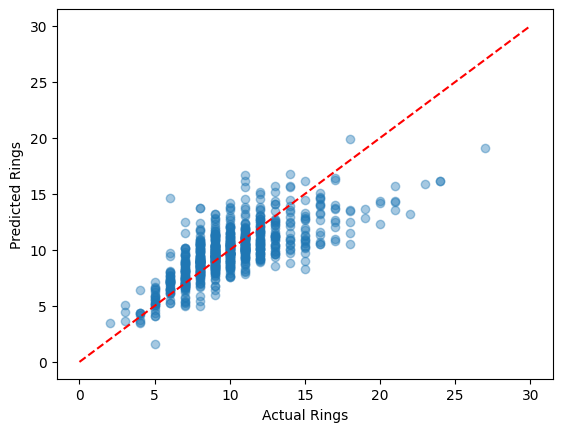

In [35]:
plt.scatter(rings_test, y_pred, alpha=0.4)
plt.plot([0, 30], [0, 30], "r--")
plt.xlabel("Actual Rings")
plt.ylabel("Predicted Rings")
plt.show()